# Gemma 4 E2B and E4B on Intent-to-SLO: zero-shot and few-shot, thinking off and on

## Context of this notebook (the request, kept here for later verification)

> - Now use "Gemma 4 E2B & E4B" model to perform the zero-shot and few shot experiment with thinking on and off
> - Prompt for zero-shot: "zs_cot_p_mc_system.txt"
> - Prompt for few-shot: "fs2_unitFixed+6_prompt.txt"
> - list out the similar analysis that you did for Qwen 3.5 4B & 9B models
> - Criticize the result and find out the caveats
> - Note findings a new file: "6.Gemma4 E2B E4B.ipynb".

## The experiments

| name | prompt | thinking | model checkpoints |
|---|---|---|---|
| `zs` | system prompt `prompts/zs_cot_p_mc_system.txt` (paper's zero-shot prompt with `cpu_capacity=millicores`) + user template `zs_p_paper_user.txt` | off | `google/gemma-4-E2B-it` (5.1B parameters stored) and `google/gemma-4-E4B-it` (8.0B stored); "E2B/E4B" are the vendor's *effective* sizes, a large part of the stored weights are per-layer embeddings |
| `fs-f2` | `prompts/fs2_unitFixed+6_prompt.txt` (unit-fixed system prompt, snapshot-verification rule, six curated examples) | off | same |
| `zs-think` | as `zs` | on | same |
| `fs-f2-think` | as `fs-f2` | on | same |

**Setup (identical to the Qwen experiments wherever the model allows):** 521 valid records, greedy decoding (temperature 0, seed 0), vLLM 0.31.0, batch 64, one H100 per run (E2B on GPU 0, E4B on GPU 1, each run alone), `max_model_len` 8,192 (zs), 12,288 (fs-f2 and zs-think) and 16,384 (fs-f2-think), 2,048 answer tokens without thinking, with thinking a budget of 4,096 thinking tokens (forced close if not finished) and 1,024 answer tokens. Scoring: S0 strict micro-F1, point estimates only. **Gemma-specific handling:** the model's own chat template with a normal system turn; thinking is switched on with `enable_thinking` (the template puts `<|think|>` into the system turn), the model writes `<|channel>thought ... <channel|>` before its answer, the runner stops stage 1 at the `<channel|>` token and, if the budget runs out, appends the same budget-forcing sentence as for Qwen plus `<channel|>`. Weights were cached outside the project (the project volume is nearly full).

**Reference runs from the earlier notebooks** (same data, prompts, decoding): Qwen3.5-4B and 9B with `zs` (millicores), `fs-f2`, `zs-think` and `fs-f2-think`.

**Two things to keep in mind throughout** (details in the critique section): (1) the few-shot prompt was designed while looking at Qwen's failures, so it may favour Qwen; (2) the dataset has a closed language and a labelling conflict that cap every score near 0.95 (notebooks 4 and 5).

## Executive summary

| question | answer |
|---|---|
| Best result for each model | **E4B: 0.939** total F1 (EM 0.869) with the few-shot prompt and thinking; **E2B: 0.902** (EM 0.781). Reference Qwen3.5 4B 0.953, 9B 0.948 |
| Does the same recipe work as for Qwen? | **Yes in direction:** few-shot lifts both models (E2B +0.41, E4B +0.09 without thinking) and thinking lifts both (E2B +0.15 to +0.26, E4B +0.04 to +0.06); the best condition is few-shot with thinking, as for Qwen |
| What differs from Qwen? | (1) **E4B is strong in zero-shot (0.793)** because it does not add the spurious `highest` tag that ruins Qwen 4B (0.348), but it answers **91% of the lookups with `null`**; (2) Gemma's thinking is **short** (median 600-1,200 tokens against 3,900-4,100 for Qwen 4B) and costs about a third of the energy; (3) both Gemma models make **numeric slips** on large byte counts (E4B "3 GB = 3,145,728,000"); (4) E2B **invents a placement** for 92% of the intents that state none when it is not thinking |
| Efficiency | Per correct SLO the cheapest run so far is **E2B few-shot without thinking (29 J)**; with thinking E4B costs 85 J and E2B 68 J against 222 J and 288 J for Qwen 4B and 9B, at 0.939 / 0.902 against 0.953 / 0.948 |
| Is the engine trustworthy? | Checked against Hugging Face transformers: identical extracted SLOs for 85-96% of 48 records and **exact-match within 2 points** of the other engine, so no bias; E2B is the noisier model |
| Biggest caveats | the few-shot prompt was designed from Qwen's failures; greedy decoding instead of the recommended sampling; single runs; a stored-versus-effective parameter mismatch against Qwen; the dataset ceiling near 0.95 hides differences between the stronger conditions (section 8) |

In [1]:
import json, re, sys
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
assert (ROOT / "src").is_dir(), "start the notebook from the llmExp/ folder"
sys.path.insert(0, str(ROOT))
from src.data_io import load_records, load_snapshot
from src.score import load_predictions, canon_list, per_record, prf
from src import analysis as A

pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 160); pd.set_option("display.max_columns", 40)
records = load_records(); recs = [r for r in records if r["meta"]["status"] == "valid"]; BY_IDX = {r["index"]: r for r in recs}
snapshot = load_snapshot()
GEMMA = ["google/gemma-4-E2B-it", "google/gemma-4-E4B-it"]
QWEN = ["Qwen/Qwen3.5-4B", "Qwen/Qwen3.5-9B"]
MODELS = GEMMA + QWEN
short = lambda m: m.split("/")[-1].replace("gemma-4-", "").replace("-it", "").replace("Qwen3.5-", "Qwen ")
tagm = lambda m: m.split("/")[-1].lower().replace(".", "")
STORED = {"google/gemma-4-E2B-it": 5.1, "google/gemma-4-E4B-it": 8.0, "Qwen/Qwen3.5-4B": 4.7, "Qwen/Qwen3.5-9B": 9.7}   # Hugging Face safetensors totals (B)
EXPS = {"zs": ("zs_p_mc", False), "fs-f2": ("fs-f2", False), "zs-think": ("zs_think_p_mc", True), "fs-f2-think": ("fs-f2_think", True)}
NOTHINK, THINK = ["zs", "fs-f2"], ["zs-think", "fs-f2-think"]
def find_run(model, exp):
    ds = [d for d in (ROOT / "outputs/runs").glob(f"{EXPS[exp][0]}_{tagm(model)}_2*") if (d / "predictions.jsonl").exists()]
    return max(ds)
RUNS = {(m, e): find_run(m, e) for m in MODELS for e in EXPS}
PRED = {k: load_predictions(d / "predictions.jsonl") for k, d in RUNS.items()}
ROWS = {k: pd.DataFrame(per_record(records, p)) for k, p in PRED.items()}
FR = {k: A.record_frame(recs, PRED[k], k[1]) for k in RUNS}
display(pd.DataFrame({f"{short(m)} {e}": {"run directory": d.name, "records": len(PRED[(m, e)])} for (m, e), d in RUNS.items()}).T)

,run directory,records
E2B zs,zs_p_mc_gemma-4-e2b-it_20261018T201324,521
E2B fs-f2,fs-f2_gemma-4-e2b-it_20261018T201706,521
E2B zs-think,zs_think_p_mc_gemma-4-e2b-it_20261018T202046,521
E2B fs-f2-think,fs-f2_think_gemma-4-e2b-it_20261018T202557,521
E4B zs,zs_p_mc_gemma-4-e4b-it_20261018T201324,521
E4B fs-f2,fs-f2_gemma-4-e4b-it_20261018T201626,521
E4B zs-think,zs_think_p_mc_gemma-4-e4b-it_20261018T202046,521
E4B fs-f2-think,fs-f2_think_gemma-4-e4b-it_20261018T202555,521
Qwen 4B zs,zs_p_mc_qwen35-4b_20261017T222900,521
Qwen 4B fs-f2,fs-f2_qwen35-4b_20261018T021842,521


## 1. Output health, thinking behaviour and cost

In [2]:
rows = {}
for (m, e), p in PRED.items():
    d = pd.DataFrame(p.values())
    en = json.loads((RUNS[(m, e)] / "energy.json").read_text()) if (RUNS[(m, e)] / "energy.json").exists() else {}
    rows[f"{short(m)} {e}"] = {"parse rate": d.parse_ok.mean(), "answers truncated": int(d.truncated.sum()),
        "answer in a ``` fence": float(d.raw_text.str.lstrip().str.startswith("```").mean()), "tokens/record (mean)": d.completion_tokens.mean(), "tokens/record (max)": d.completion_tokens.max(),
        "forced think close": int(d["forced_close"].fillna(False).sum()) if "forced_close" in d else 0,
        "think tokens (median)": d["think_tokens"].median() if "think_tokens" in d else None,
        "gen time (s)": en.get("gen_seconds"), "GPU energy (Wh)": en["gpu_energy_J"] / 3600 if en else None}
health = pd.DataFrame(rows).T
display(health.round(3))

,parse rate,answers truncated,answer in a ``` fence,tokens/record (mean),tokens/record (max),forced think close,think tokens (median),gen time (s),GPU energy (Wh)
E2B zs,0.996,0.0,0.979,168.655,708.0,0.0,NaN,61.261,5.537
E2B fs-f2,1.000,0.0,1.000,207.875,412.0,0.0,NaN,71.514,6.481
E2B zs-think,1.000,0.0,1.000,1388.213,4345.0,1.0,1232.0,232.280,19.085
E2B fs-f2-think,1.000,0.0,1.000,1268.574,3232.0,0.0,1056.0,251.073,20.048
E4B zs,1.000,0.0,1.000,178.770,305.0,0.0,NaN,95.767,9.808
E4B fs-f2,1.000,0.0,1.000,187.958,342.0,0.0,NaN,107.071,10.854
E4B zs-think,1.000,0.0,1.000,830.488,1901.0,0.0,598.0,230.286,22.065
E4B fs-f2-think,1.000,0.0,1.000,876.340,2230.0,0.0,613.0,277.451,25.877
Qwen 4B zs,1.000,0.0,0.000,167.537,310.0,0.0,NaN,NaN,NaN
Qwen 4B fs-f2,1.000,0.0,0.000,170.902,324.0,0.0,NaN,82.675,9.095


**Finding.** All Gemma runs parse (parse rate 1.0, except 2 unparseable records in E2B zero-shot) and none is truncated. **Gemma wraps its JSON in a markdown fence in 98-100% of the answers (Qwen: 0%)**; the parser handles this, but it is a format difference that a stricter evaluation would have to handle too. Without thinking Gemma answers with about the same number of tokens as Qwen (169-208 against 168-176). **With thinking the Gemma models generate far less:** mean 830-876 (E4B) and 1,269-1,388 (E2B) tokens per record against 3,590-3,973 for Qwen 4B and 2,438-3,516 for Qwen 9B, and the 4,096-token thinking cap was reached **once in 2,084 thoughts** (against 238-415 of 521 for Qwen 4B and 125-213 for Qwen 9B). Generation took 61-107 s without thinking and 230-277 s with it (Qwen 4B: 626 s with thinking), and the GPU energy for the 521 records was 5.5-10.9 Wh and 19-26 Wh.

In [3]:
# thinking behaviour of the Gemma models: length, closure, and signs of loops (repeated text) under greedy decoding
def repeat_share(text, n=8):
    w = text.split()
    if len(w) < 2 * n: return 0.0
    grams = [tuple(w[i:i + n]) for i in range(len(w) - n + 1)]
    return 1 - len(set(grams)) / len(grams)
rows = {}
for m in GEMMA:
    for e in THINK:
        d = pd.DataFrame(PRED[(m, e)].values())
        rs = d.think_text.map(repeat_share)
        rows[f"{short(m)} {e}"] = {"think tokens: median": d.think_tokens.median(), "mean": d.think_tokens.mean(), "p90": d.think_tokens.quantile(.9),
                                   "closed by the model": int(d.think_closed.sum()), "forced close (4,096 cap)": int(d.forced_close.sum()),
                                   "thoughts with >30% repeated 8-grams": int((rs > 0.3).sum()), "mean repeated 8-gram share": rs.mean(), "answers parsed": float(d.parse_ok.mean())}
display(pd.DataFrame(rows).T.round(3))
d = pd.DataFrame(PRED[(GEMMA[1], "fs-f2-think")].values())
long_ = d.sort_values("think_tokens", ascending=False).iloc[0]
print("longest E4B fs-f2-think thought: record", long_["index"], "|", int(long_["think_tokens"]), "tokens | closed:", bool(long_["think_closed"]))
print("last 300 characters of that thought:", repr(long_["think_text"][-300:]))

,think tokens: median,mean,p90,closed by the model,"forced close (4,096 cap)",thoughts with >30% repeated 8-grams,mean repeated 8-gram share,answers parsed
E2B zs-think,1232.0,1211.023,1765.0,520.0,1.0,1.0,0.013,1.0
E2B fs-f2-think,1056.0,1077.255,1649.0,521.0,0.0,0.0,0.005,1.0
E4B zs-think,598.0,648.299,1000.0,521.0,0.0,0.0,0.008,1.0
E4B fs-f2-think,613.0,687.591,1165.0,521.0,0.0,0.0,0.007,1.0


longest E4B fs-f2-think thought: record 685 | 2064 tokens | closed: True
last 300 characters of that thought: 't": null}`\n2. Storage Utilization: `{"metric": "storage_utilization", "target": {"cmp": ">=", "op": "highest", "value": 53.0}, "type": "dynamic_compute_resource", "unit": "percent"}`\n\nReviewing the value 53.0: It is a float, so it should be represented as a number.\n\nThe JSON structure looks correct.'


**Finding.** Thinking behaviour. The median thought is 598-613 tokens for E4B (90th percentile 1,000-1,165) and 1,056-1,232 for E2B (1,649-1,765); every thought but one closed by itself. Greedy decoding did not produce loops: only one of the 2,084 thoughts has more than 30% repeated 8-grams and the mean repeated share is 0.5-1.3%. So the concern that greedy decoding (the model card recommends temperature 1.0) could make the reasoning degenerate is not visible here. The longest E4B thought (2,064 tokens) is a normal drafting-and-checking text that ends with "The JSON structure looks correct." The small thinking budget used by the models also means the 4,096-token cap that limited Qwen is irrelevant for Gemma, which matters for the comparison of the two families (section 8).

## 2. Headline results (Table-7 style: strict micro-F1)

In [4]:
def pooled(df, keep=None):
    d = df if keep is None else df[keep]
    return prf(d.tp.sum(), d.fp.sum(), d.fn.sum())
rows = {}
for (m, e), df in ROWS.items():
    t = pooled(df)
    rows[(short(m), e)] = {"stored params (B)": STORED[m], "Real": pooled(df, df.source == "real")["f1"], "Synthetic": pooled(df, df.source == "synthetic")["f1"], "Total": t["f1"],
                           "precision": t["precision"], "recall": t["recall"], "EM": df.em.mean(), "Jaccard": df.jaccard.mean(), "TP": t["tp"], "FP": t["fp"], "FN": t["fn"]}
head = pd.DataFrame(rows).T; head.index.names = ["model", "experiment"]
order = [(short(m), e) for m in MODELS for e in NOTHINK + THINK]
display(head.loc[order].round(3))
tot = {(short(m), e): head.loc[(short(m), e), "Total"] for m in MODELS for e in EXPS}

stored params (B)   Real  Synthetic  Total  precision  recall     EM  Jaccard      TP     FP     FN
model   experiment                                                                                                      
E2B     zs                         5.1  0.222      0.247  0.239      0.261   0.222  0.125    0.217   259.0  735.0  910.0
        fs-f2                      5.1  0.599      0.665  0.645      0.609   0.687  0.292    0.554   803.0  516.0  366.0
        zs-think                   5.1  0.430      0.366  0.385      0.399   0.372  0.223    0.354   435.0  656.0  734.0
        fs-f2-think                5.1  0.819      0.936  0.902      0.893   0.910  0.781    0.882  1064.0  127.0  105.0
E4B     zs                         8.0  0.743      0.813  0.793      0.799   0.786  0.610    0.771   919.0  231.0  250.0
        fs-f2                      8.0  0.837      0.894  0.877      0.878   0.876  0.745    0.852  1024.0  142.0  145.0
        zs-think                   8.0  0.801      0.844  0.831      0.831   0.831  0.678    0.820   972.0  197.0  197.0
        fs-f2-think                8.0  0.974      0.925  0.939      0.939   0.939  0.869    0.931  1098.0   71.0   71.0
Qwen 4B zs                         4.7  0.310      0.364  0.348      0.358   0.339  0.119    0.262   396.0  711.0  773.0
        fs-f2                      4.7  0.804      0.875  0.854      0.833   0.877  0.649    0.809  1025.0  206.0  144.0
        zs-think                   4.7  0.514      0.555  0.543      0.546   0.541  0.288    0.470   632.0  526.0  537.0
        fs-f2-think                4.7  0.997      0.935  0.953      0.953   0.953  0.896    0.948  1114.0   55.0   55.0
Qwen 9B zs                         9.7  0.789      0.844  0.828      0.837   0.820  0.670    0.818   958.0  187.0  211.0
        fs-f2                      9.7  0.949      0.915  0.925      0.924   0.926  0.833    0.915  1083.0   89.0   86.0
        zs-think                   9.7  0.790      0.852  0.833      0.850   0.818  0.656    0.816   956.0  169.0  213.0
        fs-f2-think                9.7  1.000      0.926  0.948      0.948   0.948  0.887    0.942  1108.0   61.0   61.0

**Finding.** Total strict F1 (zero-shot / few-shot fs-f2 / zero-shot thinking / few-shot thinking): **E2B 0.239 / 0.645 / 0.385 / 0.902; E4B 0.793 / 0.877 / 0.831 / 0.939**; for reference Qwen 4B 0.348 / 0.854 / 0.543 / 0.953 and Qwen 9B 0.828 / 0.925 / 0.833 / 0.948. Exact match of the best runs: E4B 0.869, E2B 0.781 (Qwen 0.887-0.896). With the final prompt and thinking E4B is within 0.014 of both Qwen models and E2B 0.051 below Qwen 4B. As with Qwen, the real subset scores above the synthetic subset for E4B with the final prompt (0.974 against 0.925, the scope conflict of notebook 5), but not for E2B (0.819 against 0.936), whose errors are genuine mistakes rather than label conflicts.

## 3. The big picture: zero-shot vs few-shot, thinking off vs on

E2B    E4B  Qwen 4B  Qwen 9B
             prompt                                        
thinking off zero-shot       0.239  0.793    0.348    0.828
             few-shot fs-f2  0.645  0.877    0.854    0.925
thinking on  zero-shot       0.385  0.831    0.543    0.833
             few-shot fs-f2  0.902  0.939    0.953    0.948

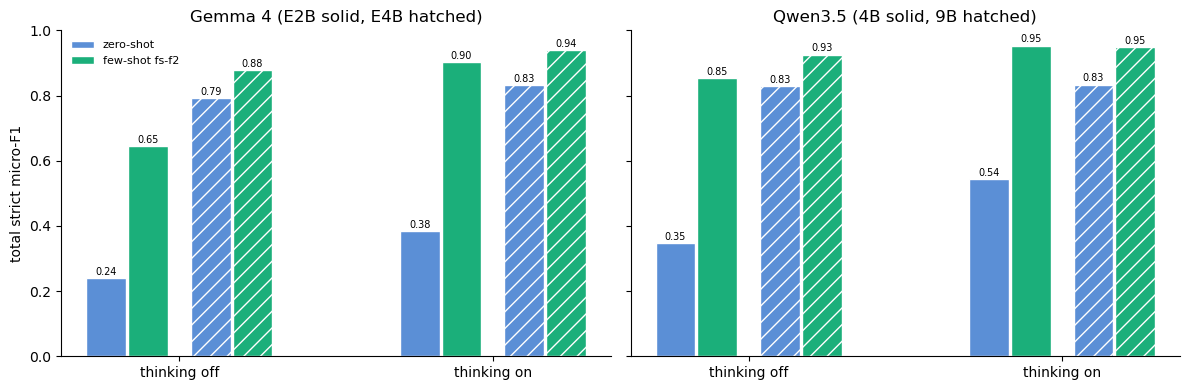

In [5]:
labels = {"zs": "zero-shot", "fs-f2": "few-shot fs-f2"}
pv = pd.DataFrame({short(m): {("thinking off", labels[p]): tot[(short(m), p)] for p in NOTHINK} | {("thinking on", labels[p]): tot[(short(m), p + "-think")] for p in NOTHINK} for m in MODELS})
pv.index.names = ["", "prompt"]; display(pv.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
colr = {"zero-shot": "#5b8fd6", "few-shot fs-f2": "#1baf7a"}
for ax, fam in zip(axes, (GEMMA, QWEN)):
    names = [short(m) for m in fam]
    for gi, state in enumerate(["thinking off", "thinking on"]):
        for mi, nm in enumerate(names):
            for pi, p in enumerate(colr):
                v = pv.loc[(state, p), nm]; x = gi * 3 + mi * 1.0 + (pi - 0.5) * 0.4 - 0.0
                ax.bar(x, v, 0.38, color=colr[p], hatch="" if mi == 0 else "//", edgecolor="white", label=f"{p}" if (gi == 0 and mi == 0) else None)
                ax.text(x, v + 0.01, f"{v:.2f}", ha="center", fontsize=7)
    ax.set_xticks([0.5, 3.5], ["thinking off", "thinking on"]); ax.set_ylim(0, 1); ax.set_title("Gemma 4 (E2B solid, E4B hatched)" if fam is GEMMA else "Qwen3.5 (4B solid, 9B hatched)")
    for s_ in ("top", "right"): ax.spines[s_].set_visible(False)
axes[0].set_ylabel("total strict micro-F1"); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Finding.** The same pattern as for Qwen: **few-shot lifts both models and thinking lifts both, and the best condition combines them.** Few-shot design: +0.41 (E2B) and +0.09 (E4B) without thinking, +0.52 and +0.11 with thinking. Thinking: +0.15 (zero-shot) and +0.26 (fs-f2) for E2B, +0.04 and +0.06 for E4B; the smaller model gains more from both, as Qwen 4B did. **E4B behaves like a stronger model than its name suggests:** its zero-shot score (0.793) is close to Qwen 9B (0.828) and far above Qwen 4B (0.348) at about 4B effective parameters by its name (8.0B stored) against 9.7B. The reason is visible in the error tables: it never adds the spurious `highest` tag. With the final prompt and thinking the four models E4B, Qwen 4B, Qwen 9B (0.939-0.953) converge at the dataset ceiling (notebook 5), and only E2B stays below (0.902).

In [6]:
def em_moves(m, a, b):
    ea, eb = FR[(m, a)].set_index("index").em, FR[(m, b)].set_index("index").em
    return int(((ea == 0) & (eb == 1)).sum()), int(((ea == 1) & (eb == 0)).sum())
rows = []
for m in MODELS:
    for name, a, b in (("few-shot design (zero-shot -> fs-f2), thinking off", "zs", "fs-f2"), ("few-shot design, thinking on", "zs-think", "fs-f2-think"),
                       ("thinking (zero-shot)", "zs", "zs-think"), ("thinking (fs-f2)", "fs-f2", "fs-f2-think")):
        up, down = em_moves(m, a, b)
        rows.append({"model": short(m), "effect": name, "F1 before": tot[(short(m), a)], "F1 after": tot[(short(m), b)], "change": tot[(short(m), b)] - tot[(short(m), a)],
                     "records fixed (EM 0->1)": up, "records broken (EM 1->0)": down})
display(pd.DataFrame(rows).round(3))

,model,effect,F1 before,F1 after,change,records fixed (EM 0->1),records broken (EM 1->0)
0,E2B,"few-shot design (zero-shot -> fs-f2), thinking off",0.239,0.645,0.406,96,9
1,E2B,"few-shot design, thinking on",0.385,0.902,0.517,301,10
2,E2B,thinking (zero-shot),0.239,0.385,0.145,61,10
3,E2B,thinking (fs-f2),0.645,0.902,0.256,265,10
4,E4B,"few-shot design (zero-shot -> fs-f2), thinking off",0.793,0.877,0.085,107,37
5,E4B,"few-shot design, thinking on",0.831,0.939,0.108,117,17
6,E4B,thinking (zero-shot),0.793,0.831,0.039,67,32
7,E4B,thinking (fs-f2),0.877,0.939,0.062,95,30
8,Qwen 4B,"few-shot design (zero-shot -> fs-f2), thinking off",0.348,0.854,0.506,289,13
9,Qwen 4B,"few-shot design, thinking on",0.543,0.953,0.410,319,2


**Finding.** Fixed versus broken records. Few-shot design without thinking: E2B fixes 96 records and breaks 9; E4B fixes 107 and **breaks 37** (Qwen: 9-13 broken). With thinking: E2B 301 fixed and 10 broken, E4B 117 fixed and 17 broken. Thinking over fs-f2: E2B 265 and 10, E4B 95 and 30. E4B's regressions without thinking (37) are mostly in the category 'other'; the cases inspected are numeric slips in the GB-to-bytes conversion (section 4.4), which the few-shot prompt does not remove and thinking mostly does.

## 4. Trends in the error patterns

In [7]:
tax = pd.DataFrame({f"{short(m)} {e}": A.error_taxonomy(recs, PRED[(m, e)]).groupby("error")["count"].sum() for m in MODELS for e in EXPS}).fillna(0).astype(int)
tax = tax.loc[tax.sum(axis=1).sort_values(ascending=False).index]
for fam in (GEMMA, QWEN):
    cols_ = [f"{short(m)} {e}" for m in fam for e in NOTHINK + THINK]
    print("Unmatched SLOs by error type:", [short(m) for m in fam]); display(tax[cols_][tax[cols_].sum(axis=1) > 0])

Unmatched SLOs by error type: ['E2B', 'E4B']


,E2B zs,E2B fs-f2,E2B zs-think,E2B fs-f2-think,E4B zs,E4B fs-f2,E4B zs-think,E4B fs-f2-think
error,,,,,,,,
wrong value,118,184,131,63,128,116,153,58
wrong ext,70,15,80,10,0,0,12,0
missed,239,12,140,2,28,3,0,1
wrong rel+ext,231,11,182,13,0,0,0,0
spurious,70,162,62,24,9,0,0,1
wrong rel+value,120,28,85,1,59,9,0,0
wrong rel,74,49,92,10,5,16,24,12
wrong ext+value,34,61,15,6,0,1,1,0
wrong value+unit,12,0,1,0,27,0,1,0


Unmatched SLOs by error type: ['Qwen 4B', 'Qwen 9B']


,Qwen 4B zs,Qwen 4B fs-f2,Qwen 4B zs-think,Qwen 4B fs-f2-think,Qwen 9B zs,Qwen 9B fs-f2,Qwen 9B zs-think,Qwen 9B fs-f2-think
error,,,,,,,,
wrong value,105,104,160,55,108,61,146,61
wrong ext,489,1,326,0,1,0,3,0
missed,96,1,12,0,28,0,53,0
wrong rel+ext,17,0,10,0,0,0,1,0
spurious,34,63,1,0,4,3,9,0
wrong rel+value,29,1,11,0,32,8,1,0
wrong rel,17,36,10,0,2,17,8,0
wrong ext+value,14,1,3,0,32,0,1,0
wrong value+unit,1,0,3,0,0,0,0,0


**Finding.** Error trends. **E2B zero-shot misuses the schema:** `wrong rel+ext` 231, `missed` 239, `wrong rel+value` 120, `wrong ext` 70 (it writes `cmp: "<"` 288 times, puts `highest`/`lowest` in the `cmp` field and sometimes `op: "set"` on thresholds); the few-shot prompt removes most of this (`missed` 239 to 12, `wrong rel+ext` 231 to 11) but creates `spurious` 162 (invented placements) and `wrong value` 184 without thinking; with thinking the residual is `wrong value` 63 and `spurious` 24. **E4B zero-shot** has none of Qwen 4B's `wrong ext` errors (0 against 489) and its errors are `wrong value` 128 (null lookups), `wrong rel+value` 59 and `wrong value+unit` 27; with the final prompt `wrong value` is 116 (58 with thinking), of which 66 and 55 are lookups and the rest numeric slips, and `wrong rel` 16 and 12. The families therefore fail differently in zero-shot (Qwen 4B: over-tagging; E4B: not reading the snapshot; E2B: schema misuse) and converge to the same residual (lookup scope and values) once the prompt and thinking are in place.

In [8]:
pm = {(m, e): A.per_metric(recs, PRED[(m, e)]) for m in MODELS for e in EXPS}
for m in GEMMA:
    tab = pd.DataFrame({e: 2 * pm[(m, e)].tp / (2 * pm[(m, e)].tp + pm[(m, e)].fp + pm[(m, e)].fn) for e in NOTHINK + THINK}); tab.insert(0, "gold SLOs", pm[(m, "zs")].gold)
    print(f"F1 per (type, metric), {short(m)}:"); display(tab[tab["gold SLOs"] > 0].round(3))

F1 per (type, metric), E2B:


gold SLOs     zs  fs-f2  zs-think  fs-f2-think
type                     metric                                                             
dynamic_compute_resource cpu_utilization          167.0  0.044  0.510     0.154        0.916
                         memory_utilization       118.0  0.059  0.854     0.077        0.924
                         storage_utilization      145.0  0.049  0.657     0.050        0.890
node_network_resource    port_utilization          35.0  0.000  0.464     0.062        0.343
placement_location       -                        390.0  0.594  0.866     0.731        0.971
static_compute_resource  cpu_capacity              80.0  0.212  0.390     0.364        0.888
                         memory_capacity          128.0  0.055  0.361     0.392        0.847
                         storage_capacity         106.0  0.042  0.306     0.289        0.868

F1 per (type, metric), E4B:


gold SLOs     zs  fs-f2  zs-think  fs-f2-think
type                     metric                                                             
dynamic_compute_resource cpu_utilization          167.0  0.778  0.789     0.772        0.946
                         memory_utilization       118.0  0.831  0.919     0.763        0.966
                         storage_utilization      145.0  0.688  0.897     0.703        0.903
node_network_resource    port_utilization          35.0  0.057  0.686     0.200        0.771
placement_location       -                        390.0  0.972  1.000     1.000        1.000
static_compute_resource  cpu_capacity              80.0  0.931  0.950     0.938        0.975
                         memory_capacity          128.0  0.593  0.656     0.719        0.784
                         storage_capacity         106.0  0.670  0.764     0.821        0.943

**Finding.** Per metric. **E4B** is already good on placement (0.972) and `cpu_capacity` (0.931, the millicores prompt works) in zero-shot, weak on `port_utilization` (0.057) and `memory_capacity` (0.593); with fs-f2 and thinking it reaches 0.90-0.98 on every metric except `port_utilization` (0.771) and `memory_capacity` (0.784). **E2B** is near zero on most metrics in zero-shot (0.04-0.06; placement 0.594, `cpu_capacity` 0.212) and with fs-f2 and thinking reaches 0.85-0.97 on utilisation, capacity and placement but only 0.343 on `port_utilization`, the weakest metric of every model. `memory_capacity` stays the weakest capacity metric for all (0.78-0.85 with thinking).

In [9]:
rows = {}
for m in MODELS:
    for e in NOTHINK + THINK:
        o = A.extremum_outcomes(recs, PRED[(m, e)]); n = int(o.sum())
        rows[f"{short(m)} {e}"] = {"lookups": n, "right op, value null": int(o.get("right op, value null (snapshot not read)", 0)), "right op, correct number": int(o.get("right op, correct number", 0)),
                                   "right op, wrong number": int(o.get("right op, wrong number", 0)), "wrong operator": int(o.get("wrong op (e.g. threshold / opposite extreme)", 0)), "metric not predicted": int(o.get("metric not predicted", 0))}
ext = pd.DataFrame(rows).T; ext["null share"] = ext["right op, value null"] / ext["lookups"]; ext["correct share"] = ext["right op, correct number"] / ext["lookups"]
display(ext.round(3))

,lookups,"right op, value null","right op, correct number","right op, wrong number",wrong operator,metric not predicted,null share,correct share
E2B zs,221,101,36,33,4,46,0.457,0.163
E2B fs-f2,221,0,115,51,51,4,0.000,0.520
E2B zs-think,221,118,34,11,4,54,0.534,0.154
E2B fs-f2-think,221,0,158,33,29,1,0.000,0.715
E4B zs,221,201,14,1,0,5,0.910,0.063
E4B fs-f2,221,0,155,66,0,0,0.000,0.701
E4B zs-think,221,138,66,12,5,0,0.624,0.299
E4B fs-f2-think,221,0,165,55,0,1,0.000,0.747
Qwen 4B zs,221,59,88,48,8,18,0.267,0.398
Qwen 4B fs-f2,221,0,158,61,1,1,0.000,0.715


**Finding.** **E4B in zero-shot answers 91% of the highest/lowest requests with `value: null` (201 of 221) and gets only 14 right**, the behaviour that Qwen 27B showed; thinking reduces it to 62% (138) and 66 correct. E2B is at 46% null (101) and 16% correct. With the few-shot prompt the null share is 0% for both (as for Qwen) and the correct share is 70% (E4B) and 52% (E2B); with thinking 75% and 72%, the same level as Qwen (70-75%). E2B also gives the wrong operator for 51 lookups without thinking (29 with it), a problem the Qwen models do not have with fs-f2. As for Qwen, the worked lookup examples are what makes the models read the snapshot.

In [10]:
def gb_class(pv, gv):
    if pv is None: return "value null"
    if not isinstance(pv, float): return "non-numeric"
    if pv == gv: return "exact (binary, = gold)"
    r = pv / gv
    if any(abs(r - (1000 / 1024) ** k) < 2e-3 for k in (1, 2, 3, 4)): return "decimal instead of binary"
    return "other value"
rows = {}
for m in MODELS:
    for e in NOTHINK + THINK:
        c = Counter(); u = Counter()
        for r in recs:
            pr = PRED[(m, e)][r["index"]]; pred = canon_list(pr["parsed"]["slos"]) if pr["parse_ok"] else []
            for g in canon_list(r["label"]["slos"]):
                if g[1] in ("memory_capacity", "storage_capacity") and g[3] is None:
                    cand = [t for t in pred if t[:3] == g[:3]]; c[gb_class(cand[0][4], g[4]) if cand else "no prediction"] += 1
                if g[1] == "cpu_capacity" and g[3] is None:
                    cand = [t for t in pred if t[:3] == g[:3]]; u["cpu: exact (millicores)" if g in pred else ("cpu: answered in cores" if cand and cand[0][5] == "cores" else "cpu: other")] += 1
        rows[f"{short(m)} {e}"] = {**c, **u}
units = pd.DataFrame(rows).T.fillna(0).astype(int); display(units)
print("gold: 158 explicit GB requests (binary), 74 explicit cpu_capacity requests (millicores)")

,no prediction,other value,decimal instead of binary,"exact (binary, = gold)",cpu: other,cpu: exact (millicores)
E2B zs,64,38,45,11,58,16
E2B fs-f2,2,93,9,54,45,29
E2B zs-think,37,9,15,97,50,24
E2B fs-f2-think,0,8,6,144,7,67
E4B zs,3,0,15,140,1,73
E4B fs-f2,0,4,48,106,3,71
E4B zs-think,0,2,2,154,0,74
E4B fs-f2-think,0,3,0,155,0,74
Qwen 4B zs,4,0,10,144,73,1
Qwen 4B fs-f2,0,18,25,115,2,72


gold: 158 explicit GB requests (binary), 74 explicit cpu_capacity requests (millicores)


**Finding.** Unit conventions. cpu_capacity works for E4B from the start (73 of 74 exact in zero-shot) and for E2B only with thinking and few-shot (16, 29, 24 and 67 of 74). **The GB conversion is where Gemma differs from Qwen:** E4B without thinking is *worse* with the few-shot prompt than in zero-shot (106 exact and 48 wrong against 140 and 15); 44 of the 48 are the mixed conversion `1 GB = 1000 MiB` (for example 3 GB becomes 3,145,728,000 instead of 3,221,225,472, ratio 0.9766), the others arithmetic slips (4 GB to 3,538,944,320). With thinking E4B is exact for 155 of 158 and E2B for 144. E2B in zero-shot has only 11 exact (64 absent, 83 wrong; for example 1 GB written as 1.024e12 bytes). These models can follow the unit rule of the prompt only when they think; without thinking they approximate the arithmetic.

In [11]:
# lookups where the global and the layer-restricted extreme differ: which scope do gold and model use? (see notebooks 4 and 5)
rows = {}
for m in MODELS:
    for e in NOTHINK + THINK:
        ex = A.extremum_choices(recs, PRED[(m, e)], snapshot); d = ex[ex["gold uses"].isin(["global", "layer"])]; c = Counter(zip(d["gold uses"], d["model uses"]))
        t = pooled(ROWS[(m, e)]); n = c[("global", "layer")]
        rows[f"{short(m)} {e}"] = {"gold=layer, model=layer": c[("layer", "layer")], "gold=global, model=layer": n, "gold=global, model=global": c[("global", "global")], "gold=layer, model=global": c[("layer", "global")],
                                   "model null/other": sum(v for (g, mu), v in c.items() if mu not in ("layer", "global")), "unmatched gold SLOs (FN)": int(t["fn"]), "F1": t["f1"],
                                   "F1 if gold=global/model=layer counted correct (DIAGNOSTIC)": 2 * (t["tp"] + n) / (2 * (t["tp"] + n) + (t["fp"] - n) + (t["fn"] - n))}
display(pd.DataFrame(rows).T.round(3))

,"gold=layer, model=layer","gold=global, model=layer","gold=global, model=global","gold=layer, model=global",model null/other,unmatched gold SLOs (FN),F1,F1 if gold=global/model=layer counted correct (DIAGNOSTIC)
E2B zs,1.0,4.0,12.0,4.0,85.0,910.0,0.239,0.243
E2B fs-f2,6.0,23.0,44.0,22.0,11.0,366.0,0.645,0.664
E2B zs-think,2.0,3.0,9.0,7.0,85.0,734.0,0.385,0.388
E2B fs-f2-think,3.0,6.0,66.0,27.0,4.0,105.0,0.902,0.907
E4B zs,0.0,1.0,2.0,0.0,103.0,250.0,0.793,0.793
E4B fs-f2,8.0,21.0,51.0,16.0,10.0,145.0,0.877,0.895
E4B zs-think,1.0,4.0,23.0,9.0,69.0,197.0,0.831,0.835
E4B fs-f2-think,28.0,52.0,23.0,3.0,0.0,71.0,0.939,0.984
Qwen 4B zs,1.0,8.0,26.0,17.0,54.0,773.0,0.348,0.355
Qwen 4B fs-f2,7.0,12.0,39.0,7.0,41.0,144.0,0.854,0.864


**Finding.** Ceiling and label conflict. For **E4B** with fs-f2 and thinking, 52 of the 71 unmatched gold SLOs are lookups where the gold uses the global extreme and the model applied the layer rule; counting them as correct (diagnostic, not a score) would give 0.984, so about 19 SLOs are genuine errors (digit-level slips such as 4 GB written as 4,294,967,300 and lookup values). For **E2B** only 6 of its 105 unmatched SLOs are label conflicts (diagnostic 0.907): its remaining errors are real. For Qwen the same diagnostic gives 0.999-1.000. So E4B is close to the dataset ceiling, E2B is not, and the equality of the strongest conditions (0.939-0.953) partly reflects the ceiling.

In [12]:
rows = {}
for m in MODELS:
    for e in NOTHINK + THINK:
        inv = tot_np = ok = tot_p = 0
        for r in recs:
            pr = PRED[(m, e)][r["index"]]; pred = canon_list(pr["parsed"]["slos"]) if pr["parse_ok"] else []
            g_pl = [t for t in canon_list(r["label"]["slos"]) if t[0] == "placement_location"]; p_pl = [t for t in pred if t[0] == "placement_location"]
            if g_pl: tot_p += 1; ok += g_pl[0] in p_pl
            else: tot_np += 1; inv += bool(p_pl)
        rows[f"{short(m)} {e}"] = {"records without placement": tot_np, "with an invented placement": inv, "invented share": inv / tot_np, "records with placement": tot_p, "placement exactly right": ok / tot_p}
display(pd.DataFrame(rows).T.round(3))

,records without placement,with an invented placement,invented share,records with placement,placement exactly right
E2B zs,131.0,31.0,0.237,390.0,0.546
E2B fs-f2,131.0,121.0,0.924,390.0,1.000
E2B zs-think,131.0,28.0,0.214,390.0,0.769
E2B fs-f2-think,131.0,23.0,0.176,390.0,1.000
E4B zs,131.0,2.0,0.015,390.0,0.951
E4B fs-f2,131.0,0.0,0.000,390.0,1.000
E4B zs-think,131.0,0.0,0.000,390.0,1.000
E4B fs-f2-think,131.0,0.0,0.000,390.0,1.000
Qwen 4B zs,131.0,2.0,0.015,390.0,0.831
Qwen 4B fs-f2,131.0,62.0,0.473,390.0,1.000


**Finding.** Placement. When a layer is stated all models place correctly with the few-shot prompt (100%), but **E2B invents a placement for 92% of the 131 intents that state none (121 records) without thinking** (24% in zero-shot, 18% with thinking), twice the rate of Qwen 4B (47%), while E4B does it for 0-2 records. The example set contains a placement in five of six examples, which E2B over-generalises. In zero-shot E2B also places correctly in only 55% of the intents that state a layer (E4B 95%, Qwen 83-94%). E4B sometimes fills the placement slot with a number (record 176: `placement=4294967296`).

In [13]:
lv = {f"{short(m)} {e}": A.grouped_f1(FR[(m, e)], "level")["F1"] for m in GEMMA for e in NOTHINK + THINK}
lvdf = pd.DataFrame(lv); lvdf.insert(0, "n", A.grouped_f1(FR[(GEMMA[0], "zs")], "level")["n"]); print("F1 by level:"); display(lvdf.round(3))
src = {f"{short(m)} {e}": A.grouped_f1(FR[(m, e)], "source")["F1"] for m in GEMMA for e in NOTHINK + THINK}; print("F1 by source:"); display(pd.DataFrame(src).T.round(3))

F1 by level:


,n,E2B zs,E2B fs-f2,E2B zs-think,E2B fs-f2-think,E4B zs,E4B fs-f2,E4B zs-think,E4B fs-f2-think
level,,,,,,,,,
1,137,0.445,0.589,0.662,0.932,0.971,0.949,0.993,1.000
2,174,0.231,0.649,0.382,0.942,0.890,0.885,0.929,0.963
3,141,0.199,0.691,0.337,0.895,0.780,0.882,0.767,0.942
4,48,0.143,0.598,0.293,0.828,0.574,0.812,0.679,0.861
5,21,0.367,0.602,0.367,0.840,0.500,0.820,0.760,0.860


F1 by source:


source,real,synthetic
E2B zs,0.222,0.247
E2B fs-f2,0.599,0.665
E2B zs-think,0.430,0.366
E2B fs-f2-think,0.819,0.936
E4B zs,0.743,0.813
E4B fs-f2,0.837,0.894
E4B zs-think,0.801,0.844
E4B fs-f2-think,0.974,0.925


**Finding.** By level, E4B zero-shot is excellent at level 1 (0.971) and falls to 0.57 and 0.50 at levels 4 and 5, where lookups appear; with fs-f2 and thinking it is 1.000 at level 1 and 0.86 at levels 4-5. E2B with fs-f2 and thinking goes from 0.932 (level 1) to 0.83-0.84 (levels 4-5). The ordering of difficulty is the same as for Qwen: it follows the number of snapshot lookups, not the number of constraints.

## 5. Qualitative analysis

In [14]:
def fmt(t):
    if t[0] == "placement_location": return f"placement={t[4]}"
    v = t[4]; vs = "null" if v is None else (f"{v:.12g}" if isinstance(v, float) else str(v))
    return f"{t[1]} {t[2]} {vs} {t[5]}" + (f" [{t[3]}]" if t[3] else "")
def classify(gold, pred):
    pc, gc = Counter(pred), Counter(gold)
    if pc == gc: return None
    ug, up = list((gc - pc).elements()), list((pc - gc).elements())
    for g in ug:
        if g[1] == "cpu_capacity" and any(t[1] == "cpu_capacity" and t[5] == "cores" for t in up): return "answered in cores"
    for g in ug:
        if g[1] in ("memory_capacity", "storage_capacity") and g[3] is None:
            for t in up:
                if t[1] == g[1] and isinstance(t[4], float) and g[4] and abs(t[4] / g[4] - (1000 / 1024) ** 3) < 2e-3: return "decimal instead of binary GB"
    for t in up:
        if t[3] in ("highest", "lowest") and any(g[:3] == t[:3] and g[3] is None for g in ug): return "spurious highest/lowest tag"
    for g in ug:
        if g[3] in ("highest", "lowest"):
            same = [t for t in up if t[:2] == g[:2]]
            if any(t[4] is None for t in same): return "snapshot not read (value null)"
            if any(t[3] == g[3] and t[4] != g[4] for t in same): return "wrong number from the snapshot"
            if any(t[3] == g[3] and t[4] == g[4] and t[2] != g[2] for t in same): return "wrong comparison (<= vs >=)"
            if same: return "wrong operator"
    if not any(g[0] == "placement_location" for g in gold) and any(t[0] == "placement_location" for t in up): return "invented placement"
    for g in ug:
        if not any(t[:2] == g[:2] for t in pred): return "missing SLO"
    return "other"
def cls_of(m, e, idx):
    r = BY_IDX[idx]; pr = PRED[(m, e)][idx]
    return classify(canon_list(r["label"]["slos"]), canon_list(pr["parsed"]["slos"]) if pr["parse_ok"] else [])
CATS = ["answered in cores", "decimal instead of binary GB", "spurious highest/lowest tag", "snapshot not read (value null)", "wrong number from the snapshot", "wrong comparison (<= vs >=)", "wrong operator", "invented placement", "missing SLO", "other"]

In [15]:
PAIRS = [("zs", "fs-f2"), ("zs-think", "fs-f2-think")]
for m in GEMMA:
    rows = {}
    for a, b in PAIRS:
        ca = {i: cls_of(m, a, i) for i in BY_IDX}; cb = {i: cls_of(m, b, i) for i in BY_IDX}
        fixed = Counter(ca[i] for i in BY_IDX if ca[i] and cb[i] is None); failed = Counter(ca[i] for i in BY_IDX if ca[i]); broken = Counter(cb[i] for i in BY_IDX if ca[i] is None and cb[i])
        rows[f"{a} -> {b}"] = {**{f"corrected: {c}": f"{fixed.get(c, 0)} of {failed.get(c, 0)}" for c in CATS}, "zero-shot exact": sum(v is None for v in ca.values()), "few-shot exact": sum(v is None for v in cb.values()),
                               "records broken (exact -> not exact)": sum(broken.values()), "failure types of the broken records": dict(broken)}
    print(f"{short(m)}: failure categories of the zero-shot answer and how many the few-shot prompt corrected"); display(pd.DataFrame(rows))

E2B: failure categories of the zero-shot answer and how many the few-shot prompt corrected


,zs -> fs-f2,zs-think -> fs-f2-think
corrected: answered in cores,0 of 0,0 of 0
corrected: decimal instead of binary GB,0 of 4,0 of 0
corrected: spurious highest/lowest tag,20 of 78,69 of 84
corrected: snapshot not read (value null),14 of 82,47 of 92
corrected: wrong number from the snapshot,4 of 23,4 of 9
corrected: wrong comparison (<= vs >=),7 of 28,13 of 18
corrected: wrong operator,0 of 2,2 of 2
corrected: invented placement,0 of 31,19 of 25
corrected: missing SLO,22 of 83,52 of 67
corrected: other,29 of 125,95 of 108


E4B: failure categories of the zero-shot answer and how many the few-shot prompt corrected


,zs -> fs-f2,zs-think -> fs-f2-think
corrected: answered in cores,0 of 0,0 of 0
corrected: decimal instead of binary GB,0 of 0,0 of 0
corrected: spurious highest/lowest tag,0 of 0,4 of 4
corrected: snapshot not read (value null),87 of 171,77 of 122
corrected: wrong number from the snapshot,1 of 1,7 of 11
corrected: wrong comparison (<= vs >=),0 of 0,1 of 1
corrected: wrong operator,0 of 0,2 of 4
corrected: invented placement,2 of 2,0 of 0
corrected: missing SLO,10 of 14,0 of 0
corrected: other,7 of 15,26 of 26


**Finding.** What the few-shot prompt corrected. For **E2B** the biggest groups are missing or malformed SLOs (22 of 83 corrected without thinking, 52 of 67 with it), the spurious tag (20 of 78, 69 of 84) and lookups with null (14 of 82, 47 of 92); it did *not* correct its invented placements without thinking (0 of 31) but did with thinking (19 of 25). For **E4B** the main correction is the null lookup (87 of 171 without thinking, 77 of 122 with it). Broken records: E2B 9 and 10, E4B **37** and 17; E4B's are mostly in the category 'other' (32), which in the cases inspected are numeric slips.

In [16]:
def show_examples(m, base, new, max_total=5, n_per_cat=1):
    seen = Counter(); shown = 0
    for idx in sorted(BY_IDX):
        if shown >= max_total: break
        cb = cls_of(m, base, idx)
        if cb is None or cls_of(m, new, idx) is not None or seen[cb] >= n_per_cat: continue
        seen[cb] += 1; shown += 1; r = BY_IDX[idx]
        print(f"--- {short(m)} | record {idx} ({r['meta']['source']}, level {r['meta']['level']}) | {base} failure type: {cb}")
        print("  intent:", r["input"]["intent"]["expression"]); print("  gold:        ", "; ".join(fmt(t) for t in canon_list(r["label"]["slos"])))
        for e in (base, new):
            pr = PRED[(m, e)][idx]; ok = cls_of(m, e, idx) is None
            print(f"  {e:<14}{'OK ' if ok else 'BAD'} ", "; ".join(fmt(t) for t in canon_list(pr["parsed"]["slos"])) if pr["parse_ok"] else "(unparseable)")
        print()
for m in GEMMA:
    print("=" * 25, short(m), ": bad in zs, exact with fs-f2 (thinking off)", "=" * 25); show_examples(m, "zs", "fs-f2")
for m in GEMMA:
    print("=" * 25, short(m), ": bad in zs-think, exact with fs-f2-think (thinking on)", "=" * 25); show_examples(m, "zs-think", "fs-f2-think", max_total=4)

========================= E2B : bad in zs, exact with fs-f2 (thinking off) =========================
--- E2B | record 10 (real, level 1) | zs failure type: other
  intent: For descartesresearch/teastore-image, please keep CPU utilization below 65%.
  gold:         cpu_utilization <= 65 percent
  zs            BAD  cpu_utilization < 65 percent
  fs-f2         OK   cpu_utilization <= 65 percent

--- E2B | record 20 (real, level 2) | zs failure type: spurious highest/lowest tag
  intent: Please deploy descartesresearch/teastore-webui and run it on the edge side, keep CPU utilization below 35%, and make sure the target node has at least 1 GB of memory.
  gold:         placement=edge; cpu_utilization <= 35 percent; memory_capacity >= 1073741824 bytes
  zs            BAD  cpu_utilization < 35 percent [lowest]; memory_capacity >= 1.024e+12 bytes [highest]; placement=edge
  fs-f2         OK   placement=edge; cpu_utilization <= 35 percent; memory_capacity >= 1073741824 bytes

--- E2B | record 2

**Finding.** Examples fixed by the few-shot prompt (bad in zero-shot, exact with fs-f2). **E2B:** a strict `<` for "below 65%" (record 10; the gold maps "below" to `<=`), the nonsense `memory_capacity >= 1.024e+12 bytes [highest]` for "1 GB of memory" together with a spurious `lowest` tag (record 20), `value: null` for a lookup (record 25), `highest` written into the comparator field (record 29) and a malformed SLO without metric (record 52). **E4B:** null lookups (records 23 and 45), a strict `<` for "below 50%" (record 118) and a placement SLO with a numeric value, `placement=4294967296`, for "place <service> ... at least 4 GB of memory" (record 176). With thinking the corrections are of the same kinds. The few-shot prompt fixes the format and the lookups; the numeric slips and the placement habit of E2B are not what it was designed for.

In [17]:
# the other direction, and what Gemma still gets wrong with the final prompt
for m in GEMMA:
    for a, b in (("zs", "fs-f2"), ("zs-think", "fs-f2-think")):
        broken = [i for i in sorted(BY_IDX) if cls_of(m, a, i) is None and cls_of(m, b, i) is not None]
        print(f"{short(m)}: exact in {a} but not in {b}: {len(broken)} records; failure types: {dict(Counter(cls_of(m, b, i) for i in broken))}")
        for i in broken[:2]:
            r = BY_IDX[i]; print(f"   record {i} [{cls_of(m, b, i)}] {r['input']['intent']['expression'][:130]}"); print("     gold:", "; ".join(fmt(t) for t in canon_list(r["label"]["slos"]))); print("     " + b + ":", "; ".join(fmt(t) for t in canon_list(PRED[(m, b)][i]["parsed"]["slos"])))
print()
for m in GEMMA:
    for e in ("fs-f2", "fs-f2-think"):
        c = Counter(cls_of(m, e, i) for i in BY_IDX if cls_of(m, e, i)); print(f"{short(m)} {e}: {sum(c.values())} records not exact; main failure types: {c.most_common(5)}")

E2B: exact in zs but not in fs-f2: 9 records; failure types: {'invented placement': 7, 'other': 2}
   record 62 [invented placement] Please schedule descartesresearch/teastore-auth and make sure the target node has at least 4 GB of memory.
     gold: memory_capacity >= 4294967296 bytes
     fs-f2: placement=edge; memory_capacity >= 8318894080 bytes
   record 65 [invented placement] I need descartesresearch/teastore-image deployed and make sure the target node has at least 2 GB of memory.
     gold: memory_capacity >= 2147483648 bytes
     fs-f2: placement=edge; memory_capacity >= 2147483648 bytes
E2B: exact in zs-think but not in fs-f2-think: 10 records; failure types: {'other': 3, 'wrong number from the snapshot': 1, 'invented placement': 6}
   record 42 [other] Please schedule descartesresearch/teastore-recommender and place it on edge nodes and make sure the target node has at least 30 GB
     gold: placement=edge; storage_capacity >= 32212254720 bytes
     fs-f2-think: placement=ed

**Finding.** Records made worse by the few-shot prompt. **E4B without thinking: 37 records, 32 of them in the failure category 'other', which in the cases inspected are numeric slips in the GB conversion** (record 27: 3 GB becomes 3,145,728,000 and 3 cores 4,000 millicores; record 50: 4 GB becomes 4,194,304,000), plus one dropped CPU threshold (record 20). **E4B with thinking: 17 records**, 12 lookup values, 2 comparators and 3 'other' cases, two of which are digit-level slips (record 50: 4,294,967,300 for 4,294,967,296; record 97: 3,221,175,472 for 3,221,225,472). **E2B: 9 and 10 records, 7 and 6 of them invented placements** (record 65: `placement=edge` for an intent that names none). The remaining failures of the final prompt are: E4B lookup values (53 of 68 with thinking), E2B invented placements (23-109) and lookup values and operators.

## 6. Cost: tokens, time and energy

In [18]:
def energy_run(m, exp):
    if m in GEMMA or exp.startswith("fs-"):
        return RUNS[(m, exp)]
    pre = {"zs": "zs_p_mc_energy", "zs-think": "zs_think_p_mc_energy"}[exp]
    return max(d for d in (ROOT / "outputs/runs").glob(f"{pre}_{tagm(m)}_2*") if (d / "energy.json").exists())
rows = {}
for m in MODELS:
    for e in NOTHINK + THINK:
        d = energy_run(m, e); en = json.loads((d / "energy.json").read_text()); p = load_predictions(d / "predictions.jsonl"); n = en["n_records"]; tp = int(pooled(ROWS[(m, e)])["tp"])
        rows[f"{short(m)} {e}"] = {"stored params (B)": STORED[m], "gen time (s)": en["gen_seconds"], "GPU energy (Wh)": en["gpu_energy_J"] / 3600, "J / record": en["gpu_energy_J"] / n,
                                   "mean power (W)": en["gpu_energy_J"] / en["gen_seconds"], "tokens / record": np.mean([r["completion_tokens"] for r in p.values()]), "F1": tot[(short(m), e)], "J / correct SLO": en["gpu_energy_J"] / tp}
cost = pd.DataFrame(rows).T; display(cost.round(2))
print("GPU-only energy during generation, batch 64, each run alone on one H100 NVL; Qwen zero-shot energy from the earlier energy re-runs")

,stored params (B),gen time (s),GPU energy (Wh),J / record,mean power (W),tokens / record,F1,J / correct SLO
E2B zs,5.1,61.26,5.54,38.26,325.37,168.65,0.24,76.96
E2B fs-f2,5.1,71.51,6.48,44.78,326.27,207.88,0.65,29.06
E2B zs-think,5.1,232.28,19.08,131.87,295.79,1388.21,0.38,157.94
E2B fs-f2-think,5.1,251.07,20.05,138.53,287.46,1268.57,0.90,67.83
E4B zs,8.0,95.77,9.81,67.77,368.71,178.77,0.79,38.42
E4B fs-f2,8.0,107.07,10.85,75.00,364.94,187.96,0.88,38.16
E4B zs-think,8.0,230.29,22.06,152.46,344.93,830.49,0.83,81.72
E4B fs-f2-think,8.0,277.45,25.88,178.80,335.76,876.34,0.94,84.84
Qwen 4B zs,4.7,80.42,8.85,61.18,396.39,167.54,0.35,80.49
Qwen 4B fs-f2,4.7,82.68,9.09,62.84,396.02,170.90,0.85,31.94


GPU-only energy during generation, batch 64, each run alone on one H100 NVL; Qwen zero-shot energy from the earlier energy re-runs


**Finding.** Cost. Without thinking the Gemma models are about as cheap as Qwen: E2B 38-45 J per record (the cheapest of all runs), E4B 68-75 J (Qwen 4B 61-63, 9B 101-103); their GPU draws less power (290-370 W against 395-400 W for Qwen), so the runs are less saturated. **With thinking Gemma is much cheaper: E4B 152-179 J per record against 461-475 (Qwen 4B) and 470-613 (Qwen 9B), E2B 132-139 J**, because the thoughts are two to four times shorter. Per correct SLO: E2B fs-f2 **29 J** (the lowest so far; Qwen 4B 32 J, E4B 38 J, Qwen 9B 49 J); with thinking E2B 68 J (F1 0.90), E4B 85 J (0.94), Qwen 4B 222 J (0.95), Qwen 9B 288 J (0.95). So for a thinking configuration E4B reaches 98% of Qwen 4B's F1 at 38% of its energy.

## 7. Gemma 4 against Qwen3.5

In [19]:
g = pd.DataFrame({e: {short(m): tot[(short(m), e)] for m in MODELS} for e in NOTHINK + THINK})
g.insert(0, "stored params (B)", [STORED[m] for m in MODELS]); g["thinking gain (zs)"] = g["zs-think"] - g["zs"]; g["thinking gain (fs-f2)"] = g["fs-f2-think"] - g["fs-f2"]; g["few-shot gain (thinking off)"] = g["fs-f2"] - g["zs"]
display(g.round(3))
em = pd.DataFrame({e: {short(m): head.loc[(short(m), e), "EM"] for m in MODELS} for e in NOTHINK + THINK}); print("exact match:"); display(em.round(3))
perm = {}
for e in ("fs-f2", "fs-f2-think"):
    for m in MODELS:
        t = pd.DataFrame({"F1": 2 * pm[(m, e)].tp / (2 * pm[(m, e)].tp + pm[(m, e)].fp + pm[(m, e)].fn)}); perm[f"{short(m)} {e}"] = t["F1"]
print("per-metric F1 with the final prompt:"); display(pd.DataFrame(perm).loc[lambda d: pm[(GEMMA[0], "zs")].gold.reindex(d.index) > 0].round(3))

,stored params (B),zs,fs-f2,zs-think,fs-f2-think,thinking gain (zs),thinking gain (fs-f2),few-shot gain (thinking off)
E2B,5.1,0.239,0.645,0.385,0.902,0.145,0.256,0.406
E4B,8.0,0.793,0.877,0.831,0.939,0.039,0.062,0.085
Qwen 4B,4.7,0.348,0.854,0.543,0.953,0.195,0.099,0.506
Qwen 9B,9.7,0.828,0.925,0.833,0.948,0.005,0.023,0.097


exact match:


,zs,fs-f2,zs-think,fs-f2-think
E2B,0.125,0.292,0.223,0.781
E4B,0.610,0.745,0.678,0.869
Qwen 4B,0.119,0.649,0.288,0.896
Qwen 9B,0.670,0.833,0.656,0.887


per-metric F1 with the final prompt:


E2B fs-f2  E4B fs-f2  Qwen 4B fs-f2  Qwen 9B fs-f2  E2B fs-f2-think  E4B fs-f2-think  Qwen 4B fs-f2-think  Qwen 9B fs-f2-think
type                     metric                                                                                                                                             
dynamic_compute_resource cpu_utilization          0.510      0.789          0.910          0.928            0.916            0.946                0.946                0.946
                         memory_utilization       0.854      0.919          0.941          0.958            0.924            0.966                0.966                0.966
                         storage_utilization      0.657      0.897          0.789          0.945            0.890            0.903                0.938                0.931
node_network_resource    port_utilization         0.464      0.686          0.571          0.629            0.343            0.771                0.886                0.857
placement_location       -                        0.866      1.000          0.926          0.996            0.971            1.000                1.000                1.000
static_compute_resource  cpu_capacity             0.390      0.950          0.975          0.975            0.888            0.975                0.975                0.975
                         memory_capacity          0.361      0.656          0.633          0.688            0.847            0.784                0.836                0.805
                         storage_capacity         0.306      0.764          0.745          0.943            0.868            0.943                0.943                0.943

**Finding.** Gemma against Qwen. **Zero-shot:** E4B (0.793) is far better than Qwen 4B (0.348) and close to Qwen 9B (0.828); E2B (0.239) is below Qwen 4B. **Few-shot without thinking:** E4B 0.877 is about level with Qwen 4B (0.854) and below Qwen 9B (0.925); E2B 0.645 is well below. **With thinking and few-shot:** E4B 0.939 against 0.953 (Qwen 4B) and 0.948 (Qwen 9B), E2B 0.902; all within the resolution of single runs for E4B. The size comparison is not clean: E4B has 8.0B stored parameters (about 4B effective) against 4.7B for Qwen 4B and 9.7B for Qwen 9B. Thinking helps the smaller model of each family more (E2B +0.15/+0.26, Qwen 4B +0.20/+0.10, against +0.04/+0.06 for E4B and +0.01/+0.02 for Qwen 9B). Per metric, with the final prompt E4B is stronger than Qwen 4B on `storage_utilization` (0.897 against 0.789 without thinking) and weaker on `port_utilization` with thinking (0.771 against 0.886).

## 8. Critique and caveats

In [20]:
# (a) is the engine faithful? vLLM greedy output against Hugging Face transformers greedy output on the same prompts (scripts/validate_gemma_hf.py, thinking off)
rows, notes = {}, []
for m, f in (("E2B", "gemma_hf_validation_e2b.json"), ("E4B", "gemma_hf_validation_e4b.json")):
    vp = ROOT / "outputs" / f
    if vp.exists():
        v = json.loads(vp.read_text()); notes.append(v.get("note", ""))
        for k, d in v["summary"].items(): rows[f"{m} {k}"] = d
display(pd.DataFrame(rows).T.round(3)); print(notes[0] if notes else "validation files not found")

,records compared,identical answer text,identical parsed SLOs,"exact match, Hugging Face","exact match, vLLM",exact only in Hugging Face,exact only in vLLM
E2B zs,48.0,0.833,0.896,0.146,0.146,0.0,0.0
E2B fs-f2,48.0,0.854,0.854,0.333,0.354,0.0,1.0
E4B zs,48.0,0.896,0.917,0.625,0.625,0.0,0.0
E4B fs-f2,48.0,0.938,0.958,0.688,0.667,1.0,0.0


google/gemma-4-E2B-it; transformers vs vLLM, greedy, first 48 valid records, thinking off, max 400 new tokens; exact text equality is not expected across engines (bf16 kernels), identical parsed SLOs is the relevant measure


**Finding.** Engine check against Hugging Face transformers (48 records, thinking off, greedy). **Parsed SLOs are identical for 90% and 85% of the records for E2B (zero-shot, few-shot) and 92% and 96% for E4B**, and the **exact-match rate differs by at most 2 points between the engines** (E2B zero-shot 0.146 against 0.146, few-shot 0.333 against 0.354; E4B 0.625 against 0.625 and 0.688 against 0.667), with differences in both directions (one record exact only in vLLM, one only in Hugging Face, none in the zero-shot cases). So vLLM does not bias the scores, but individual answers do change with the numerical path, more for E2B: **differences of a few points between conditions, especially for E2B, are within engine noise.**

In [21]:
# (b) how much do the Gemma results depend on decisions made while designing for Qwen? the fs-f2 examples cover which failures?
for m in MODELS:
    print(f"{short(m)}: zs exact {int((FR[(m, 'zs')].em == 1).sum())}, fs-f2 exact {int((FR[(m, 'fs-f2')].em == 1).sum())}, fs-f2-think exact {int((FR[(m, 'fs-f2-think')].em == 1).sum())}")
# (c) differences smaller than the resolution of a single greedy run
close = [(a, b, abs(tot[(a, 'fs-f2-think')] - tot[(b, 'fs-f2-think')])) for a, b in [("E4B", "Qwen 4B"), ("E4B", "Qwen 9B"), ("E2B", "Qwen 4B")]]
print("fs-f2-think F1 gaps:", {f"{a} vs {b}": round(g_, 3) for a, b, g_ in close})
# (d) ceiling: unmatched SLOs explained by the dataset's scope conflict (diagnostic F1 from section 4)

E2B: zs exact 65, fs-f2 exact 152, fs-f2-think exact 407
E4B: zs exact 318, fs-f2 exact 388, fs-f2-think exact 453
Qwen 4B: zs exact 62, fs-f2 exact 338, fs-f2-think exact 467
Qwen 9B: zs exact 349, fs-f2 exact 434, fs-f2-think exact 462
fs-f2-think F1 gaps: {'E4B vs Qwen 4B': np.float64(0.014), 'E4B vs Qwen 9B': np.float64(0.009), 'E2B vs Qwen 4B': np.float64(0.051)}


**Finding.** Cross-checks. The exact-match counts per condition are given above. The four fs-f2-think gaps between Gemma and Qwen are 0.009-0.014 (E4B) and 0.051 (E2B against Qwen 4B); gaps of this size are within what a single greedy run and the engine noise (section 8.1) can produce, so the ranking of E4B, Qwen 4B and Qwen 9B with the final prompt and thinking cannot be resolved with these data.

### 8.3 Critique of the results and the caveats

**What the results do and do not show**

1. **The few-shot prompt is not model-neutral.** `fs2_unitFixed+6` was designed while looking at Qwen's failures (the spurious `highest` tag, null lookups, the unit conventions). It fits Qwen's weaknesses and misses Gemma's: E2B invents a placement for 92% of the intents that state none (the examples contain a placement in five of six), E4B approximates GB-to-bytes arithmetic, E2B misuses the comparator field in zero-shot. So Gemma's few-shot scores are partly a measure of *prompt mismatch*, not of the model, and a Gemma-specific prompt (a no-placement example, a conversion table) might change them; this experiment cannot say by how much.
2. **The two families are not run under the same thinking regime.** Qwen thinks 3,600-4,000 tokens and is cut by the 4,096-token cap on 46-80% of the 4B's records; Gemma thinks 600-1,200 tokens and is almost never cut. The Qwen thinking results may therefore be underestimates and the Gemma ones are not capped, so "Gemma thinking costs a third of Qwen's energy" is true for these runs, and at least partly a statement about how long each model chooses to think, not about efficiency per unit of reasoning.
3. **Greedy decoding is not what the vendor recommends.** The model card specifies temperature 1.0, top-p 0.95, top-k 64. We used greedy for comparability with Qwen. No degenerate loops appeared (section 1), but the scores might differ under the recommended sampling and the results are single runs.
4. **Stored and effective parameters.** E2B and E4B have 5.1B and 8.0B stored parameters (a large share are per-layer embeddings); the names refer to effective sizes. Comparing "E4B with Qwen 4B" matches names, not parameter counts, memory footprint or energy per token.
5. **The dataset ceiling hides differences.** The strongest conditions of E4B, Qwen 4B and Qwen 9B all sit within 0.014 of each other, and the label conflict of notebook 5 explains most of their remaining errors (E4B: 52 of 71). Ranking the models at the top of the scale is not possible here; the informative differences are the weaker conditions (zero-shot, no thinking, E2B).
6. **The closed language of the dataset** (notebook 5) means these results describe a controlled sub-language. They say nothing about negation, ranges, several services or noisy text; Gemma's robustness to other wording was not tested (no template-shift probe was run for Gemma).
7. **No uncertainty estimate.** One greedy run per cell, no confidence intervals; with the engine noise of section 8.1 differences below about 0.03 should not be interpreted, which includes most of the Gemma-versus-Qwen gaps.

**Technical caveats**

8. **Engine.** vLLM 0.31.0 with a new architecture; the check against Hugging Face (8.1) shows no bias in accuracy but record-level disagreement of 4-15%, highest for E2B. It covers thinking off and the first 48 records only.
9. **Thinking implementation.** Stage 1 stops at the `<channel|>` token and stage 2 re-feeds the thought text plus `<channel|>`; this reproduces the template but is not byte-identical to native generation (the text is re-tokenised), and the forced-close sentence was written for Qwen. It only matters for forced closes, which occurred once.
10. **Output format.** Gemma wraps almost every answer in a code fence and writes `cmp: "="` for placement; the parser and the canonicalisation absorb both, so the scores are unaffected, but a stricter format check would penalise Gemma.
11. **Energy.** GPU-only, one H100, batch 64. Gemma runs draw 290-370 W and Qwen 395-400 W, so utilisation differs and the energy ratios depend on batching; they are not a property of the models alone.
12. **Scope of the experiment.** Only the zero-shot (millicores) and fs-f2 prompts were run, as requested; fs-f1, the template-shift probe and the other Gemma 4 sizes (12B, 26B-A4B, 31B) were not.

## 9. Conclusions and next steps

- **Gemma 4 follows the Qwen pattern:** few-shot and thinking both help, most for the smaller model, and the combination gives the best results (E4B 0.939, E2B 0.902). The final prompt makes E4B equal to the Qwen models within the resolution of the data.
- **Where Gemma is different:** E4B is a strong zero-shot model but never reads the snapshot without examples; both models make numeric slips in the unit conversion unless they think; E2B invents placements and misuses the schema in zero-shot; Gemma's thinking is short and about three times cheaper in energy.
- **What to do next, if the comparison matters:** (1) write a Gemma-specific variant of the final prompt (a no-placement example, an explicit conversion table) and re-run, to separate model weakness from prompt mismatch; (2) repeat the strongest conditions with the recommended sampling and several seeds; (3) run the template-shift probe on Gemma; (4) use a harder or relabelled evaluation (notebook 5) so that conditions at the top of the scale can be ranked; (5) add the 12B and 26B-A4B Gemma 4 models to separate size from family.